<a href="https://colab.research.google.com/github/laoneya31/IAT360-Group-18/blob/main/notebooks/Lavanya_Licences_Freeze_FinalEvaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><b>Licences, Frozen Layers and Final Evaluation</b></h1></center>
<center>IAT 360 Group 18 (Lavanya, Daksh, Philip, Jasper)</center>

**Tasks:** licence check (record it in `docs/DATA_SOURCES.md`), tune `freeze`, final evaluation on our 120-photo test set, pick worked and failed examples.

# 1. Environment

Use a GPU runtime: **Runtime > Change runtime type > T4 GPU**. The shared Drive folder must be in your My Drive: right-click `IAT360-Group 18` in *Shared with me* and choose **Organize > Add shortcut**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Clone our repo and the official YOLO repo. YOLO is pinned to one release so all four members train with identical code.

In [2]:
import os, sys
REPO = "/content/IAT360-Group-18"
YOLO_TAG = "v8.4.204"

if os.path.exists(REPO):
    !git -C {REPO} pull --ff-only
else:
    !git clone https://github.com/laoneya31/IAT360-Group-18 {REPO}
# The folder must not be called "ultralytics": /content is on sys.path, so it would hide the real package.
if not os.path.exists("/content/yolo_repo"):
    !git -c advice.detachedHead=false clone -q --depth 1 --branch {YOLO_TAG} https://github.com/ultralytics/ultralytics /content/yolo_repo
%pip install -q /content/yolo_repo kagglehub
%cd {REPO}

Cloning into '/content/IAT360-Group-18'...
remote: Enumerating objects: 304, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 304 (delta 1), reused 0 (delta 0), pack-reused 299 (from 3)
Receiving objects: 100% (304/304), 179.19 MiB | 17.88 MiB/s, done.
Resolving deltas: 100% (75/75), done.
Updating files: 100% (180/180), done.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/IAT360-Group-18


Importing required libraries, and checking the software and hardware.

In [3]:
import glob, hashlib, random, shutil
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import ultralytics
ultralytics.checks()
from ultralytics import YOLO

sys.path.insert(0, f"{REPO}/src")
import fruit_yolo as fy

fy.check_config()
print("Team Drive folder:", fy.find_team_drive())
print("Baseline settings:", fy.BASELINE)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.5/112.6 GB disk)
config.yaml: 6 classes, order matches.
Team Drive folder: /content/drive/MyDrive/IAT360-Group 18
Baseline settings: {'model': 'yolov8s.pt', 'epochs': 50, 'patience': 20, 'imgsz': 640, 'batch': 16, 'optimizer': 'AdamW', 'lr0': 0.001, 'momentum': 0.9, 'warmup_bias_lr': 0.0, 'seed': 0, 'deterministic': True}


## Hyperparameter tuning

`freeze`, baseline none. Freezing the first N layers keeps the pretrained features and trains faster, but gives the model less room to learn rot.

Only this one value changes. Everything else stays at the shared baseline, so the difference from the baseline can be attributed to it.

In [4]:
assert fy.fetch_dataset(), "Dataset is not on Drive yet."
OWNER = "Lavanya"
PARAM, VALUES = fy.TUNING_PLAN[OWNER]
RUNS = [f"{PARAM}_{v}" for v in VALUES]

for name, value in zip(RUNS, VALUES):
    weights = fy.train_run(name, OWNER, overrides={PARAM: value})
    fy.evaluate(name, weights)

Extracted fruit_freshness.zip (130.3 MB, splits ['test', 'train', 'val']) to /content/IAT360-Group-18/datasets/fruit_freshness
GPU: Tesla T4
config.yaml: 6 classes, order matches.
New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freez

,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000
freeze_10,Lavanya,freeze=10,0.8387,0.9135,0.9282,0.9208,0.9634,0.7987,0.9254,0.9458,36.0,64,-0.0355
freeze_15,Lavanya,freeze=15,0.8157,0.9331,0.9018,0.9172,0.9600,0.7957,0.9035,0.9542,36.3,64,-0.0384
freeze_5,Lavanya,freeze=5,0.8682,0.9340,0.9553,0.9446,0.9766,0.8276,0.9587,0.9792,37.8,64,-0.0066


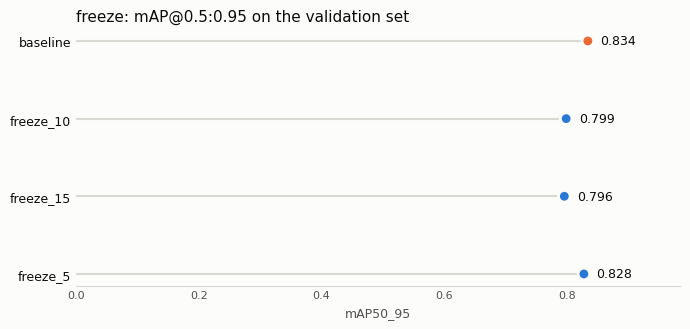

freeze_5 {'epochs_run': 50, 'best_epoch': 48, 'final_train_loss': 0.6041, 'final_val_loss': 0.9508, 'lowest_val_loss': 0.9505, 'val_loss_rise_after_best': 0.0004, 'train_val_gap': 0.3468, 'reading': 'val loss flattened with train loss: reasonable fit'}
freeze_10 {'epochs_run': 50, 'best_epoch': 42, 'final_train_loss': 0.6447, 'final_val_loss': 1.1218, 'lowest_val_loss': 1.0981, 'val_loss_rise_after_best': 0.0237, 'train_val_gap': 0.477, 'reading': 'val loss flattened with train loss: reasonable fit'}
freeze_15 {'epochs_run': 50, 'best_epoch': 49, 'final_train_loss': 0.7318, 'final_val_loss': 1.1318, 'lowest_val_loss': 1.1305, 'val_loss_rise_after_best': 0.0012, 'train_val_gap': 0.3999, 'reading': 'val loss still falling at the end: likely underfit, train longer'}


In [5]:
table = fy.compare_runs(names=["baseline"] + RUNS)
display(table)
fy.plot_comparison(table, f"{PARAM}: mAP@0.5:0.95 on the validation set",
                   save_to=fy.output_root() / "figures" / f"tuning_{PARAM}.png")
plt.show()
for name in RUNS:
    print(name, fy.fit_report(name))

### My results

No freeze value beat the baseline (mAP50-95 0.834, seed noise 0.0115).

- freeze=5: 0.828, a tie (-0.007). It had the best rotten recall (0.959 against 0.926), but that is one run.
- freeze=10: 0.799, worse (-0.035).
- freeze=15: 0.796, worse (-0.038), and still underfitting at epoch 50.

Freezing the early layers costs nothing because COCO pretraining already handles edges and colours. Freezing the whole backbone stops the model from learning rot textures (mould, browning, wrinkles), and rotten banana drops the most. For the final model, keep nothing frozen. Full write-up: report/Lavanya_Freeze.md.

Make a zip of your runs for GitHub: unzip it at the top of the repo and commit.

In [6]:
fy.package_results(RUNS)

Unzip at the top of the repo, then commit: /content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip


'/content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip'

## Final evaluation on our 120 photos

Run this once Philip has trained the final model. The test set is used **only here**, so it stays a fair measure.

In [ ]:
assert fy.fetch_dataset(), "Dataset is not on Drive yet."
weights = fy.weights_path("final")
results = {split: fy.evaluate("final", weights, split=split) for split in ("val", "test")}
results["baseline on test"] = fy.evaluate("baseline", fy.weights_path("baseline"), split="test")
display(pd.DataFrame({s: {k: r[k] for k in fy.METRIC_COLUMNS} for s, r in results.items()}).round(3))
display(pd.DataFrame(results["test"]["per_class"]).T.round(3))

Confusion matrix on the test set.

In [ ]:
figures = fy.output_root() / "figures"
display(Image.open(figures / "final_test" / "confusion_matrix_normalized.png").resize((720, 540)))

Worked and failed examples. Green boxes are true labels, orange boxes are predictions.

In [ ]:
scored = fy.score_images(weights, split="test")
fy.show_examples(scored, correct=True, n=6, save_to=figures / "final_test" / "examples_correct.png"); plt.show()
fy.show_examples(scored, correct=False, n=6, save_to=figures / "final_test" / "examples_incorrect.png"); plt.show()

### Results

The final model (baseline settings with `lr0=0.0003`) is much worse on our 120 photos than on the validation set: mAP@0.5:0.95 falls from 0.843 to 0.286, and rotten recall from 0.943 to 0.406. It still beats a model with the baseline settings on the test set (0.286 against 0.229, rotten recall 0.406 against 0.200).

- **Crowded scenes:** most errors are missed fruit (202 of 483). In one store display (`daksh_012`) all 21 fruit were missed. The training images rarely hold more than a few fruit.
- **Bagged fruit** is missed.
- **Early rot:** rotten fruit was called fresh 28 times, usually when the rot was a few brown spots.
- **Banana bunches** cause most false alarms (93 of 153), partly because our labels box bunches inconsistently.

The model learned clean public photos rather than real store displays. Real store photos with many fruit and early-rot examples would help more than any of the hyperparameters we tuned.